# Artificial Intelligence in Health Care

# NB2: How a Neural Network Learns
### Autograd, one epoch by hand, and the ways training goes wrong

In NB1 you set three weights by hand. This notebook is about where those numbers
come from when nobody chooses them.

Same dataset as NB1: UCI Heart Disease

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import keras
from keras import layers

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix

warnings.filterwarnings("ignore")
SEED = 42
keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.grid": True, "grid.alpha": 0.3})
print("keras", keras.__version__, "| backend", keras.backend.backend())

keras 3.15.1 | backend torch


---
## 1 Data, split, and where preprocessing belongs

Three lines to load, then one decision that matters more than any
hyperparameter you will touch today.

In [2]:
from ucimlrepo import fetch_ucirepo

heart = fetch_ucirepo(id=45)
X_df = heart.data.features
y = (heart.data.targets["num"] > 0).astype(int).values

# generate train, validation, and test splits (60% / 20 % / 20 %)
X_tr_df, X_tmp_df, y_tr, y_tmp = train_test_split(
    X_df, y, test_size=0.40, random_state=SEED, stratify=y)

X_va_df, X_te_df, y_va, y_te = train_test_split(
    X_tmp_df, y_tmp, test_size=0.50, random_state=SEED, stratify=y_tmp)

print(f"train {len(y_tr):>4}  ({100*y_tr.mean():.1f}% positive)")
print(f"val   {len(y_va):>4}  ({100*y_va.mean():.1f}% positive)")
print(f"test  {len(y_te):>4}  ({100*y_te.mean():.1f}% positive)")

train  181  (45.9% positive)
val     61  (45.9% positive)
test    61  (45.9% positive)


### A plain random split is fine *here*, and that is unusual

Heart Disease has **one row per patient**. No identifier, no repeats. So splitting
rows at random splits patients at random, and nothing leaks.

**Note:** `stratify=y` ensures similar proportions of classes in each set

Almost no clinical dataset is like this. In your first assignment one patient
contributes many hospital encounters, and a random split over rows puts the same
person on both sides.

**Do not take this notebook's simple split as the normal case.** It is the
exception, and it is why we can spend the time here on the model instead.

### Check for continuous and categorical (nominal, ordinal) features

Thirteen columns, four kinds of variable, three different things to do with them.
Scaling them all identically is the default move, and for three columns it is wrong.

| Kind | Columns | What to do |
|---|---|---|
| **Continuous** | `age`, `trestbps`, `chol`, `thalach`, `oldpeak` | impute + scale |
| **Ordinal / count** | `slope`, `ca` | impute + scale (we treat them as continuous) |
| **Binary** | `sex`, `fbs`, `exang` | leave them; scaling a 0/1 column changes nothing a weight cannot absorb; or one-hot |
| **Nominal** | `cp`, `restecg`, `thal` | **one-hot** |

**Remember ordinal vs. nominal:** Look at `thal` to see why the last row matters. Its codes are **3 = normal,
6 = fixed defect, 7 = reversible defect**. Feed that in as a number and you have
told the model that the step from normal to a fixed defect is *three times* the
step from fixed to reversible, because 6 − 3 = 3 and 7 − 6 = 1. Those gaps are an
artefact of how somebody numbered a codebook in 1988. `cp` (four types of chest
pain) and `restecg` (three ECG findings) have the same defect in milder form.

The imputation has to match the kind too: a **median of nominal codes** is a
category picked by arithmetic accident, so those columns get `most_frequent`.

In [3]:
CONTINUOUS = ["age", "trestbps", "chol", "thalach", "oldpeak", "slope", "ca"] # scale ordinal codes like continuous
BINARY     = ["sex", "fbs", "exang"]
NOMINAL    = ["cp", "restecg", "thal"]     # unordered codes -> one-hot encoding

# Preprocessing pipeline for the three types of features
prep = ColumnTransformer([
      ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("scale",  StandardScaler())]), CONTINUOUS),
      ("bin", SimpleImputer(strategy="most_frequent"), BINARY),
      ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                        ("onehot", OneHotEncoder(drop="first", 
                                                 handle_unknown="ignore"))]),
       NOMINAL),
])


# Preprocessing is FITTED ON THE TRAINING FOLD ONLY, then applied to the others.

X_tr = prep.fit_transform(X_tr_df).astype("float32")   # fit + transform
X_va = prep.transform(X_va_df).astype("float32")       # transform only
X_te = prep.transform(X_te_df).astype("float32")       # transform only

y_tr_f = y_tr.astype("float32")
y_va_f = y_va.astype("float32")

n_cont = len(CONTINUOUS)                 # ColumnTransformer emits in declared order

print("13 raw columns ->", X_tr.shape[1], "model inputs")
print("shapes:", X_tr.shape, X_va.shape, X_te.shape)


13 raw columns -> 17 model inputs
shapes: (181, 17) (61, 17) (61, 17)


---
## 2 Autograd (one look under the hood)

To improve a weight you need to know which way to move it. That means the
derivative of the loss with respect to that weight.

Computing derivatives by hand for a million weights is impossible. **Automatic
differentiation** does it for you, exactly, at roughly the cost of one extra
forward pass. You will only look at it directly here, in this section.

Start with something you can check in your head: $f(w) = w^2$, so
$\frac{df}{dw} = 2w$, which at $w = 3$ is $6$.

In [4]:
w = torch.tensor(3.0, requires_grad=True)   # "track what happens to this number"

f = w ** 2                                  # forward
f.backward()                                # backward: fill in w.grad

print("f(3)      =", float(f))
print("df/dw     =", float(w.grad), "   (by hand: 2*w = 6)")

f(3)      = 9.0
df/dw     = 6.0    (by hand: 2*w = 6)


### Now something that is actually a loss

For one patient with label $y$ and predicted logit $z = \mathbf{w}\cdot\mathbf{x} + b$,
binary cross-entropy is

$$L = -\big[\,y\log\sigma(z) + (1-y)\log(1 - \sigma(z))\,\big]$$

and the derivative with respect to a single weight $w_j$ has a famously clean form:

$$\frac{\partial L}{\partial w_j} = \big(\sigma(z) - y\big)\,x_j$$

**(predicted probability − truth) × input.** That is the entire learning signal.
Let us verify autograd agrees.

In [5]:
xi = torch.tensor(X_tr[0], dtype=torch.float32)
yi = torch.tensor(float(y_tr[0]))

W = torch.zeros(X_tr.shape[1], requires_grad=True)
b = torch.zeros(1, requires_grad=True)

z = torch.dot(W, xi) + b
loss = torch.nn.functional.binary_cross_entropy_with_logits(z, yi.reshape(1))
loss.backward()

p = torch.sigmoid(z).item()
by_hand = (p - float(yi)) * xi.numpy()      # (sigma(z) - y) * x

print("predicted probability  sigma(z) = %.4f   (weights are all zero)" % p)
print("true label                    y = %.0f" % float(yi))
print()
print("dL/dW, by hand   :", np.round(by_hand[:5], 5), "...")
print("dL/dW, by autograd:", np.round(W.grad.numpy()[:5], 5), "...")
print()
print("max absolute difference: %.2e" % np.abs(by_hand - W.grad.numpy()).max())

predicted probability  sigma(z) = 0.5000   (weights are all zero)
true label                    y = 0

dL/dW, by hand   : [ 0.58223  0.75848  0.16602 -0.03339 -0.08113] ...
dL/dW, by autograd: [ 0.58223  0.75848  0.16602 -0.03339 -0.08113] ...

max absolute difference: 0.00e+00


The two agree to numerical precision.

**Why this matters, and why you will not do it again.** Every framework you will
ever use is doing exactly this, for every weight, on every batch. You have now
seen it. From here on, Keras calls `backward()` for you and you can stop thinking
about it. This is the point of using Keras.

Notice one thing before moving on: with all weights at zero the model predicts
0.5 for everybody, and the gradient is proportional to how wrong that is.

---
## 3 A baseline you already know

Before any network: fit a baseline model you can compare to.

In [17]:
lr_model = LogisticRegression(max_iter=2000)
lr_model.fit(X_tr, y_tr)

p_va_lr = lr_model.predict_proba(X_va)[:, 1]
p_te_lr = lr_model.predict_proba(X_te)[:, 1]

print("logistic regression   val AUROC %.4f   test AUROC %.4f"
      % (roc_auc_score(y_va, p_va_lr), roc_auc_score(y_te, p_te_lr)))

print("Probabilities for the first 5 test samples:\n ", p_te_lr[:5].round(4))


logistic regression   val AUROC 0.9383   test AUROC 0.9307
Probabilities for the first 5 test samples:
  [0.0351 0.2384 0.4697 0.9829 0.0518]


---
## 4 The same thing in Keras

A logistic regression *is* a one-neuron network (Remember: you built one by hand in NB1).
Here it is again, this time fitted rather than hand-set.

In [7]:
def make_logreg():
    m = keras.Sequential([layers.Input(shape=(X_tr.shape[1],)), layers.Dense(1)])
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-2),
              loss=keras.losses.BinaryCrossentropy(from_logits=True), # loss for binary classification with logits (not porbabilities)
              metrics=[keras.metrics.AUC(from_logits=True, name="auc")])
    return m


keras.utils.set_random_seed(SEED)
m = make_logreg()
hist = m.fit(X_tr, y_tr_f, validation_data=(X_va, y_va_f),
             epochs=100, batch_size=32, verbose=0) # set verbose=1 to see the training progress

# Apply the sigmoid function to the model's output (logits) to get probabilities
# Note: if we used `from_logits=False` in the loss function and sigmoid as activation,
# we would not need to apply the sigmoid here.
def probs(model, A):
    return 1 / (1 + np.exp(-model.predict(A, verbose=0).ravel()))

print("keras one-neuron net  val AUROC %.4f   test AUROC %.4f"
      % (roc_auc_score(y_va, probs(m, X_va)), roc_auc_score(y_te, probs(m, X_te))))
print()
print("history keys:", list(hist.history.keys())) # for tracking training process

keras one-neuron net  val AUROC 0.9318   test AUROC 0.9145

history keys: ['auc', 'loss', 'val_auc', 'val_loss']


Two models, the same mathematics, comparable scores. Nothing has been gained yet. Boring ...

---
## 5 One epoch by hand: what `fit()` actually did (backpropagation)

You will never write this loop again. Run it once so that `fit()` stops being a
black box. Do you recognize the structure?

Five steps, repeated for every batch:

1. **clear** the previous batch's gradients
2. **forward propagate** — compute predictions
3. **loss** — how wrong they were
4. **backward** — `∂loss/∂weight` for every weight (that is §2 autograd)
5. **update** — take a small step against the gradient

To make the comparison exact we start both from **zero weights**, use plain SGD,
the same learning rate, the same batch size, and **no shuffling**.

In [8]:
LR, BS = 0.1, 32
n_feat = X_tr.shape[1]

# ---------- by hand, with torch ---------------------------------------
Wm = torch.zeros(n_feat, requires_grad=True)
bm = torch.zeros(1, requires_grad=True)
Xt = torch.tensor(X_tr); yt = torch.tensor(y_tr_f)

# loop over entire training set once (one epoch), in batches of size BS
# Note: usally this is done for multiple epochs, but here we just do one epoch to compare with Keras
for start in range(0, len(Xt), BS):
    # split the training data into batches of size BS (batch size)
    xb, yb = Xt[start:start + BS], yt[start:start + BS]
    
    if Wm.grad is not None:                              # 1. clear
        Wm.grad.zero_(); bm.grad.zero_()
    zb = xb @ Wm + bm                                    # 2. forward (use @ operator for matrix multiplication)
    lb = torch.nn.functional.binary_cross_entropy_with_logits(zb, yb)   # 3. loss
    lb.backward()                                        # 4. backward (calculate gradients)
    with torch.no_grad():                                # 5. update (weights and bias)
        Wm -= LR * Wm.grad
        bm -= LR * bm.grad

# ---------- the same epoch, via Keras ---------------------------------
mk = keras.Sequential([layers.Input(shape=(n_feat,)), layers.Dense(1)])
mk.set_weights([np.zeros((n_feat, 1), dtype="float32"),
                np.zeros(1, dtype="float32")])
mk.compile(optimizer=keras.optimizers.SGD(learning_rate=LR),
           loss=keras.losses.BinaryCrossentropy(from_logits=True))
mk.fit(X_tr, y_tr_f, epochs=1, batch_size=BS, shuffle=False, verbose=0)

Wk = mk.get_weights()[0].ravel()
print("first 5 weights, by hand :", np.round(Wm.detach().numpy()[:5], 6))
print("first 5 weights, by Keras:", np.round(Wk[:5], 6))
print()
print("max absolute difference  : %.2e" % np.abs(Wm.detach().numpy() - Wk).max())

first 5 weights, by hand : [ 0.050079  0.030659 -0.003903 -0.106914  0.086107]
first 5 weights, by Keras: [ 0.050079  0.030659 -0.003903 -0.106914  0.086107]

max absolute difference  : 7.45e-09


The same numbers, to numerical precision. `fit()` is those five lines, wrapped in
a progress bar.

**That is the last time you need to think about it.** Everything from here uses
`fit()`. 

Now you know what it is doing when a loss refuses to go down and the network does not learn.

---
## 6 Let's build and train a real neural network

This is what you will write, when implementing neural networks with Keras.
1. Let us build the model architecture from input layer, over hidden layers to the output layer.
2. Define the optimizer, hyperparameters, loss and tracking metrics
3. Fit i.e. train the model
4. Investigate the training curves


In [ ]:
def build_model(hidden=64):
    m = keras.Sequential([
        layers.Input(shape=(n_feat,)),
        # 1st hidden layer: 64 neurons (default), ReLU activation
        layers.Dense(hidden, activation="relu"),        
        # 2nd hidden layer: 32 neurons (default), ReLU activation
        layers.Dense(hidden // 2, activation="relu"),
        # output layer: 1 neuron, no activation (logits; apply sigmoid later for probabilities)
        layers.Dense(1),
    ])
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss=keras.losses.BinaryCrossentropy(from_logits=True),
              metrics=[keras.metrics.AUC(from_logits=True, name="auc")])
    return m


keras.utils.set_random_seed(SEED)
model = build_model()
model.summary()  # print model architecture

# Fit the model and track history of training and validation loss/metrics:  
h = model.fit(X_tr, y_tr_f, validation_data=(X_va, y_va_f), epochs=200,
              batch_size=32, verbose=0)

auc = roc_auc_score(y_va, probs(m, X_va))
print(f"Finished training: val AUROC {auc:.4f}")



Finished training: val AUROC 0.9232


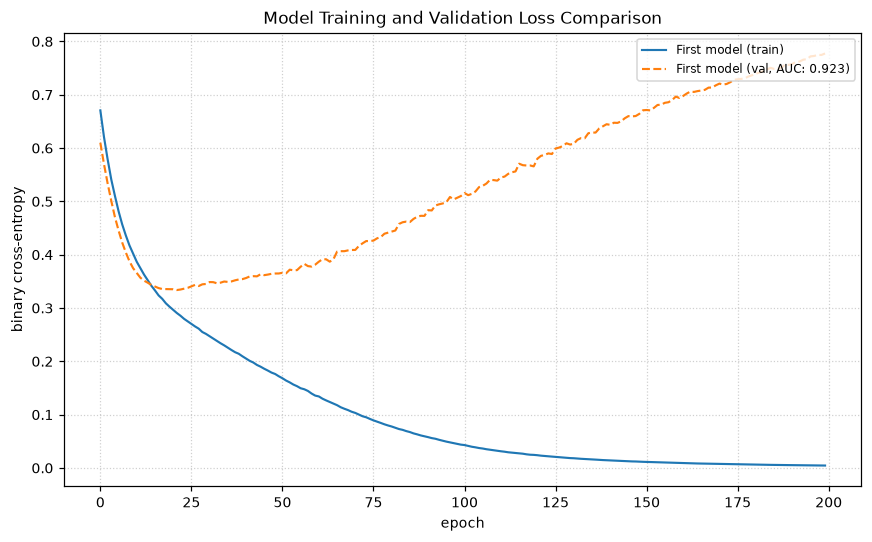

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 64)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,797 (38.27 KB)

 Trainable params: 3,265 (12.75 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,532 (25.52 KB)

In [ ]:
# Plot the training and validation loss curves:
plt.figure(figsize=(8, 5))

plt.plot(h.history["loss"], lw=1.4, label=f"First model (train)")
plt.plot(h.history["val_loss"], linestyle="--", lw=1.4, label=f"First model (val, AUC: {auc:.3f})")

plt.title("Model Training and Validation Loss Comparison")
plt.xlabel("epoch")
plt.ylabel("binary cross-entropy")
plt.legend(fontsize=8, loc="upper right")
plt.grid(True, linestyle=":", alpha=0.6) # Added for better readability on a single plot
plt.tight_layout()
plt.show()


If you look at the training curve, we see that the model **overfits the training data** (validation AUC starts rising from 25 epochs).

---
## 7 Overfitting, and three ways to fight it

With 181 training patients and a network that has thousands of parameters,
memorising the training set is not a risk —> it is the default outcome.

What can we do?

In [ ]:
# Add regularization techniques to the model: L2 regularization, dropout, and early stopping.

def build_reg(hidden=64, p_drop=0.0, l2=0.0):
    # add L2 regularization to the kernel of the Dense layers if l2 > 0
    reg = keras.regularizers.l2(l2) if l2 else None
    m = keras.Sequential([
        layers.Input(shape=(n_feat,)),
        layers.Dense(hidden, activation="relu", kernel_regularizer=reg),
        # add dropout layer after the first hidden layer 
        layers.Dropout(p_drop), 
        layers.Dense(hidden // 2, activation="relu", kernel_regularizer=reg),
        # add dropout layer after the second hidden layer
        layers.Dropout(p_drop),
        layers.Dense(1),
    ])
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss=keras.losses.BinaryCrossentropy(from_logits=True),
              metrics=[keras.metrics.AUC(from_logits=True, name="auc")])
    return m

# Put fit into a function to easily run multiple experiments 
# with different regularization techniques.
def run_reg(label, epochs=200, early=False, **kw): # **kw allows passing additional keyword arguments to build_reg ()
    keras.utils.set_random_seed(SEED)
    m = build_reg(**kw)
    # define callbacks for early stopping if early=True
    cbs = []
    if early:
        cbs = [keras.callbacks.EarlyStopping(monitor="val_auc", mode="max",
                                             patience=20, # number of epochs to wait for improvement before stopping
                                             restore_best_weights=True)]
    h = m.fit(X_tr, y_tr_f, validation_data=(X_va, y_va_f), epochs=epochs,
              batch_size=32, verbose=0, callbacks=cbs)
    auc = roc_auc_score(y_va, probs(m, X_va))
    return label, m, h, auc


runs = [
    run_reg("no regularization"),
    run_reg("L2 = 1e-2",        l2=1e-2),
    run_reg("dropout = 0.4",    p_drop=0.4),
    run_reg("early stopping",   early=True),
]
for label, _, h, auc in runs:
    print(f"{label:<20}  epochs run {len(h.history['loss']):>3}   val AUROC {auc:.4f}")

no regularization     epochs run 200   val AUROC 0.9069
L2 = 1e-2             epochs run 200   val AUROC 0.9297
dropout = 0.4         epochs run 200   val AUROC 0.9232
early stopping        epochs run  39   val AUROC 0.9361


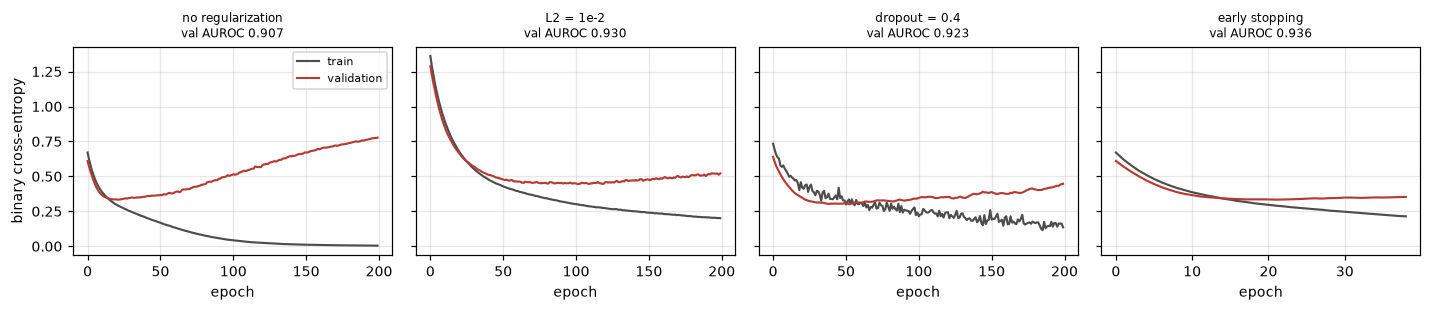

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(13, 2.9), sharey=True)
for ax, (label, _, h, auc) in zip(axes, runs):
    ax.plot(h.history["loss"], color="0.3", lw=1.4, label="train")
    ax.plot(h.history["val_loss"], color="#b53a36", lw=1.4, label="validation")
    ax.set_title(f"{label}\nval AUROC {auc:.3f}", fontsize=8)
    ax.set_xlabel("epoch")
axes[0].set_ylabel("binary cross-entropy"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

### Read the curves, do not just admire them (ok, maybe a little bit)

- **No regularization.** Training loss walks steadily towards zero while
  validation loss bottoms out early and then climbs. Everything after that
  turning point is memorisation.
- **L2** penalises large weights, so the two curves stay closer together.
- **Dropout** switches off units at random during training, forcing redundancy.
  Training loss looks *worse* which is the mechanism working, not failing.
- **Early stopping** simply refuses to run past the turning point. With
  `restore_best_weights=True` it also rewinds to the best epoch, which is not the
  default and is almost always what you want.

Look at the scores rather than the pictures. All three regularizers beat the
unregularized model (0.907): L2 reaches 0.930, dropout 0.923, and **early stopping
is the best at 0.936**. Not because it regularises more cleverly, but because it
simply stopped at epoch 39 instead of running to 200, and kept the weights from
the best epoch.

**Now the caveat that matters more than the ranking.** The validation set here is
**61 patients**. Differences of two or three points of AUROC on 61 people are not
measurable, they are within the noise, and a different seed can reorder them.
What you may conclude is the direction: unregularized training on a dataset this
small overfits (with that number of parameters), and every one of these three does something about it. What you may
*not* conclude is that dropout beat L2, or that early stopping beat both.

That is worth remembering twice over. On a small dataset the cheapest intervention
(stop before you overfit) tends to do as well as the sophisticated ones. And a
gap you cannot measure is not a result. Say both plainly in UE1 if you find the
same; later we will look into methods (a bootstrap interval on the difference) for
deciding when a gap is real.

---

**What you should be able to do now:** build, compile and fit a Keras model; read
a learning curve and say what to change; explain why a scaler is fitted on the
training fold only; and say what `fit()` is doing on each batch.

**What is still missing:** whether the numbers this model outputs
can be trusted as probabilities, what threshold to use, and whether any of it
would help a patient. That comes later and UE1 is marked before it, so those
questions are not asked of you yet.